# 01 — La serie de triage: qué mide y qué no

**Escrito el 2026-09-22. Corregido el 2026-09-29.** Este cuaderno cuenta el camino entero: lo
que se creyó al escribirlo, las figuras y las lecturas de entonces, y **lo que se supo
después**. Donde algo resultó falso no se borra: queda visible y debajo lleva un recuadro
«Corrección del 2026-09-29» con qué cambió y de dónde sale el número nuevo
(`docs/CONTEXTO.md`, «Los cuadernos cuentan la historia completa»).

## Qué contesta este cuaderno

Antes de preguntarse si el clima mueve las consultas, hay que saber cómo se comporta la
serie **sola**. Ese es todo el objetivo aquí. Cinco preguntas, en orden:

1. **¿Cuánta gente viene, y va a más o a menos?**
2. **¿Cuándo vienen?** — la hora, el día de la semana, el mes.
3. **¿Qué tipo de hospital es este?** — qué fracción es urgencia real.
4. **¿La caída de los últimos dos años es real?**
5. **¿Cuánto tarda la atención, y sirve como medida de saturación?**

Y una sexta, añadida el 2026-09-29, que es la respuesta que faltaba a la cuarta:
**¿quién explica la caída?** (sección 4.2).

## Premisas

- El desenlace del proyecto es **el conteo total de triages** por ventana de tiempo. No el
  motivo, no el nivel, no un subgrupo (`CLAUDE.md`).
- **Todos los registros se tratan como verídicos**: un triage es alguien que sintió la
  necesidad de consultar, sea cual sea el nivel que le pusieron.
- Un día **sin ninguna fila** en el total no es «cero pacientes»: urgencias no cierra. Es una
  **caída del registro** y cuenta como dato ausente (sección 0).

## Cómo leerlo

Cada figura va seguida de su lectura y de **sus límites**. Una figura sin eso al lado no es
un resultado: es un dibujo. Donde un número contradice algo que se creía antes, se dice.
**Toda cifra de una lectura sale de una salida de este cuaderno**, salvo las que se citan
explícitamente de otro cuaderno o documento.

## De dónde salen los datos

Agregados ya extraídos, sin dato personal. **Este cuaderno no se conecta a SQL Server**: corre
entero sin acceso a la historia clínica, que es lo que permite que otra persona reproduzca
las figuras.

| Archivo | Qué es | Fuente original | Cómo se regenera |
|---|---|---|---|
| `salidas/triage_horario.parquet` | triages por día × hora | `DIM_TRIAGE.HCTFECTRI`, base del SES Hospital Universitario de Caldas, solo `GROUP BY` | **sin script** (consulta del 2026-09-21); se reconstruye sumando `triage_nivel` sobre el nivel |
| `salidas/triage_diario.parquet` | triages por día | ídem | **sin script**, ídem |
| `salidas/triage_nivel.parquet` | día × hora × nivel de urgencia | `DIM_TRIAGE.HCNCLAURGTR` → `DIM_HCNCLAURGTR` | `python -m extraccion --series` |
| `salidas/triage_estancia.parquet` | por día: n, media y máximo de `HCCFECSAL − HCCFECTUR` | `DIM_TRIAGE` → `DIM_HCNCONTRDT` | `python -m extraccion --series` |
| `salidas/triage_entidad.parquet` | día × hora × entidad administradora | `DIM_TRIAGE.GEENENTADM` → `DIM_ENTIDAD` | `python -m extraccion --entidad`; se agrupa con `extraccion.entidades.clasificar` |
| `calendarios/calendario_Colombia.csv` | festivos, puentes, vacaciones | calendario oficial de Colombia | `python calendarios/calendario_colombia.py` |

**Corte:** todo llega hasta el **2026-09-20**. El 21 de septiembre está incompleto en
`triage_diario` (la extracción cortó ese día a media mañana) y `triage_nivel` llega a un 22
también parcial.

> **Corrección del 2026-09-29.** La versión anterior decía «los agregados se regeneran con
> `python -m extraccion --series`» → ese comando escribe `triage_nivel`, `triage_edad` y
> `triage_estancia`, **no** `triage_diario` ni `triage_horario`, que salieron de una consulta
> suelta del 2026-09-21 y no tienen script (`embedding/docs/HANDOFF.md`). La celda siguiente
> comprueba que `triage_horario` coincide casilla a casilla con `triage_nivel` sumado sobre el
> nivel, así que el dato es reproducible aunque el archivo no lo sea.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from clustering.visualizaciones import datos, figuras
from extraccion.entidades import clasificar

# Paleta de los cuadernos 06 y 07: categoricos en orden fijo
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUDO,
    "grid.color": "#e6e5e1", "grid.linewidth": .6, "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": TINTA, "font.size": 10, "legend.frameon": False})

FIN = "2026-09-20"          # el 21 esta incompleto
def hasta_fin(t):
    t = t.copy(); t["dia"] = pd.to_datetime(t["dia"]); return t[t["dia"] <= FIN]

total    = hasta_fin(datos.marco(datos.total()))                                 # dia x hora
nivel    = hasta_fin(pd.read_parquet(RAIZ / "salidas" / "triage_nivel.parquet"))  # dia x hora x nivel
estancia = hasta_fin(pd.read_parquet(RAIZ / "salidas" / "triage_estancia.parquet"))
entidad  = hasta_fin(clasificar(pd.read_parquet(RAIZ / "salidas" / "triage_entidad.parquet")))

serie_bruta = datos.serie_diaria(total)          # todos los dias del rango; sin filas = NULO
print(f"{total['n'].sum():,} triages   {total['dia'].nunique():,} dias con filas de "
      f"{len(serie_bruta):,} del calendario   {serie_bruta.index.min():%Y-%m-%d} a {serie_bruta.index.max():%Y-%m-%d}")

# triage_horario no tiene script: se comprueba contra triage_nivel, que si lo tiene
a = nivel.groupby(["dia", "hora"])["n"].sum()
b = total.set_index(["dia", "hora"])["n"]
j = pd.concat([a, b], axis=1, keys=["nivel", "horario"]).fillna(0)
print(f"casillas dia x hora donde horario != suma de nivel: {(j.nivel != j.horario).sum()} de {len(j):,}")

433,298 triages   2,453 dias con filas de 2,455 del calendario   2020-01-01 a 2026-09-20
casillas dia x hora donde horario != suma de nivel: 0 de 55,833


---
# 0. Antes de empezar: huecos y caídas del registro

*Sección añadida el 2026-09-29.* La versión anterior daba por hecho que la serie no tenía
huecos (sección 1.2). No era así. Aquí se buscan de dos formas:

- **Días sin ninguna fila.** Urgencias no cierra, así que un día sin registros es una caída
  del sistema, no un día sin pacientes. Van como **nulo**.
- **Días con menos del 40 % de lo esperado, fuera de COVID** (regla del cuaderno 06). Lo
  esperado sale de un control de día de la semana, festivos y nivel de cada año, ajustado en
  log fuera del periodo COVID (marzo de 2020 a febrero de 2022), igual que en el 07. Como
  segunda comprobación, sin modelo: la razón contra la mediana del mismo día de la semana en
  las ±4 semanas.

In [2]:
CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad",
       "es_temporada_fin_anio", "es_regreso_colegio"]
dias = serie_bruta.index
cal = (pd.read_csv(RAIZ / "calendarios" / "calendario_Colombia.csv", parse_dates=["fecha"])
         .set_index("fecha")[CAL + ["dia_semana"]].apply(pd.to_numeric, errors="coerce")
         .fillna(0).reindex(dias))
Z = pd.concat([pd.get_dummies(cal["dia_semana"].astype(int), prefix="d", drop_first=True).astype(float),
               cal[CAL],
               pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)],
              axis=1)
Z.insert(0, "c", 1.0)
COVID = ("2020-03-15", "2022-02-28")
fuera_covid = ~dias.to_series().between(*COVID).values
ly = np.log(serie_bruta + 0.5)
ok = fuera_covid & serie_bruta.notna().values
beta, *_ = np.linalg.lstsq(Z.values[ok], ly.values[ok], rcond=None)
esperado = pd.Series(np.exp(Z.values @ beta), index=dias)
razon = serie_bruta / esperado

# comprobacion sin modelo: mediana del mismo dia de la semana en +-4 semanas
mediana = pd.Series(np.nan, index=dias)
for dw in range(7):
    s = serie_bruta[dias.dayofweek == dw]
    mediana[s.index] = s.rolling(9, center=True, min_periods=5).median()
razon2 = serie_bruta / mediana

sin_filas = serie_bruta.index[serie_bruta.isna()]
CAIDOS = razon.index[(razon < 0.4) & fuera_covid]
print("dias sin ninguna fila:", [f"{d:%Y-%m-%d}" for d in sin_filas])
print("\nfuera de COVID, por debajo del 40 % de lo esperado:")
for d in CAIDOS:
    print(f"  {d:%Y-%m-%d} ({datos.DIAS[d.dayofweek]})  {serie_bruta[d]:.0f} triages, esperados {esperado[d]:.0f}"
          f"  -> {100*razon[d]:.0f} %   (contra la mediana del mismo dia: {100*razon2[d]:.0f} %)")
print("\nsegunda comprobacion, por debajo del 40 % de la mediana del mismo dia:",
      [f"{d:%Y-%m-%d}" for d in razon2.index[(razon2 < 0.4) & fuera_covid]])
print("para contexto, entre 40 y 60 % de lo esperado:",
      {f"{d:%Y-%m-%d}": f"{100*razon[d]:.0f} %" for d in razon.index[(razon >= .4) & (razon < .6) & fuera_covid]})
print(f"dentro de COVID hay {int(((razon < .4) & ~fuera_covid).sum())} dias bajo el 40 %: son el confinamiento, no caidas")

# desde aqui, las caidas parciales cuentan como nulo en el TOTAL
serie = serie_bruta.copy(); serie[CAIDOS] = np.nan
total   = total[~total["dia"].isin(CAIDOS)]
nivel   = nivel[~nivel["dia"].isin(CAIDOS)]
entidad = entidad[~entidad["dia"].isin(CAIDOS)]
print(f"\nserie para el resto del cuaderno: {int(serie.notna().sum()):,} dias validos, {int(serie.isna().sum())} nulos")

dias sin ninguna fila: ['2024-03-19', '2024-03-20']

fuera de COVID, por debajo del 40 % de lo esperado:
  2024-03-21 (Jueves)  40 triages, esperados 233  -> 17 %   (contra la mediana del mismo dia: 17 %)

segunda comprobacion, por debajo del 40 % de la mediana del mismo dia: ['2024-03-21']
para contexto, entre 40 y 60 % de lo esperado: {'2026-08-10': '50 %'}
dentro de COVID hay 31 dias bajo el 40 %: son el confinamiento, no caidas

serie para el resto del cuaderno: 2,452 dias validos, 3 nulos


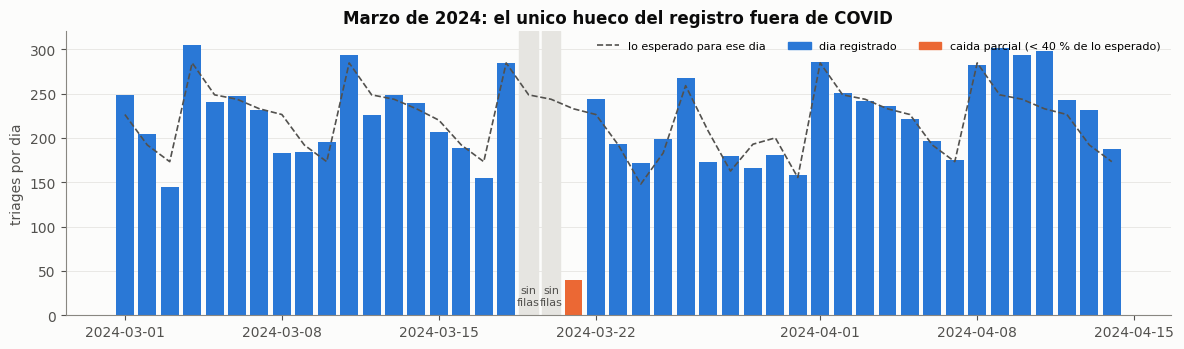

In [3]:
v = serie_bruta.loc["2024-03-01":"2024-04-14"]
fig, ax = plt.subplots(figsize=(12, 3.6))
colores = [NARANJA if d in CAIDOS else AZUL for d in v.index]
ax.bar(v.index, v.fillna(0), color=colores, width=.8)
ax.plot(esperado.loc[v.index].index, esperado.loc[v.index], color=TINTA2, lw=1.2, ls="--", label="lo esperado para ese dia")
for d in v.index[v.isna()]:
    ax.axvspan(d - pd.Timedelta(hours=10), d + pd.Timedelta(hours=10), color="#e6e5e1", zorder=0)
    ax.text(d, 12, "sin\nfilas", ha="center", fontsize=8, color=TINTA2)
from matplotlib.patches import Patch
ax.set_ylabel("triages por dia"); ax.set_title("Marzo de 2024: el unico hueco del registro fuera de COVID")
ax.legend(handles=[ax.get_lines()[0], Patch(color=AZUL, label="dia registrado"),
                   Patch(color=NARANJA, label="caida parcial (< 40 % de lo esperado)")],
          loc="upper right", ncol=3, fontsize=8)
ax.grid(axis="y"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## Lectura

**Hay un hueco, y es uno solo.** El **19 y el 20 de marzo de 2024** no tienen ninguna fila, y
el **21** tiene 40 triages cuando se esperaban unos 230 (el 17 %). Es una caída del
registro en tres días seguidos, no una caída de pacientes: el 18 y el 22 son días normales.

- Las dos comprobaciones, con modelo y sin él, marcan **solo el 21 de marzo de 2024** como caída
  parcial fuera de COVID. Coincide con el cuaderno 07.
- El día más bajo que queda después es el **10 de agosto de 2026, al 50 %**. No es una caída
  del registro: es el día del terremoto, que el cuaderno 06 midió (−50 % el día del sismo).
  Se queda.
- **Dentro de COVID** hay decenas de días bajo el 40 %. Son el confinamiento y tampoco se
  tocan: es demanda real que cayó.

**Regla que queda:** en el **total**, un día sin filas es nulo y un día con menos del 40 % de
lo esperado fuera de COVID se excluye. Rellenar con cero sigue siendo correcto para
**subconjuntos**, porque una banda de edad o una EPS sí pueden tener cero un día.

### Límites
- El 40 % es un umbral elegido, no medido. Entre el 40 y el 60 % solo queda el terremoto, así
  que mover el umbral en ese tramo no cambia nada.
- Una caída del registro de **una parte** del día que deje más del 40 % no se detecta aquí.

---
# 1. El volumen — y la primera corrección

## 1.1 Media diaria por mes y año

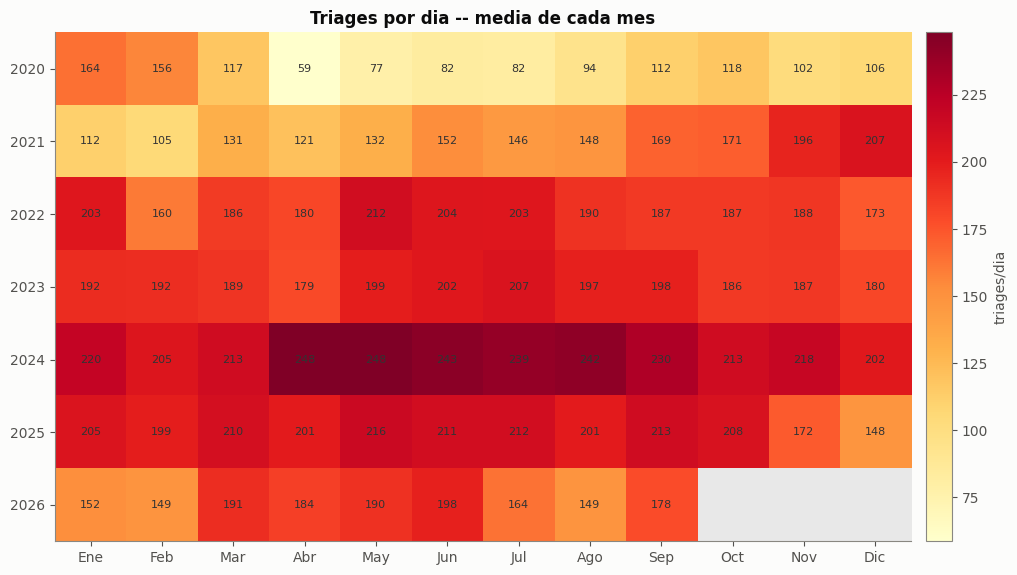

Media diaria por anio:
  2020    105.7
  2021    149.3
  2022    189.6
  2023    192.4
  2024    226.9
  2025    199.6
  2026    172.6

Pico: 2024 con 226.9
2026: 172.6  ->  -23.9% desde el pico

como se calculaba el 22-09 (con el 21-sep incompleto y el 21-mar-2024 dentro): 2024 226.4, 2026 172.3, caida -23.9 %

sin 2020: pico Jun 202, valle Feb 169, amplitud 19.7 %
2020: enero 164 -> abril 59  (-64 %)


In [4]:
fig = figuras.mes_anio(serie, titulo="Triages por dia -- media de cada mes")
plt.show()

anual = serie.groupby(serie.index.year).mean()
print("Media diaria por anio:")
for a, v in anual.items():
    print(f"  {a}   {v:6.1f}")
print(f"\nPico: {anual.idxmax()} con {anual.max():.1f}")
print(f"2026: {anual.loc[2026]:.1f}  ->  {100*(anual.loc[2026]/anual.max()-1):+.1f}% desde el pico")

vieja = datos.serie_diaria(datos.total())      # como el 22-09: hasta el 21-sep y con el 21-mar-2024
print(f"\ncomo se calculaba el 22-09 (con el 21-sep incompleto y el 21-mar-2024 dentro): "
      f"2024 {vieja['2024'].mean():.1f}, 2026 {vieja['2026'].mean():.1f}, "
      f"caida {100*(vieja['2026'].mean()/vieja['2024'].mean()-1):+.1f} %")

sin2020 = serie[serie.index.year > 2020]
m = sin2020.groupby(sin2020.index.month).mean()
print(f"\nsin 2020: pico {datos.MESES[m.idxmax()-1]} {m.max():.0f}, valle {datos.MESES[m.idxmin()-1]} {m.min():.0f}, "
      f"amplitud {100*(m.max()/m.min()-1):.1f} %")
m20 = serie["2020"].groupby(serie["2020"].index.month).mean()
print(f"2020: enero {m20[1]:.0f} -> abril {m20[4]:.0f}  ({100*(m20[4]/m20[1]-1):+.0f} %)")

## Lectura

**La serie no crece. Subió hasta 2024 y lleva dos años cayendo.**

| 2020 | 2021 | 2022 | 2023 | **2024** | 2025 | 2026 |
|---|---|---|---|---|---|---|
| 105,7 | 149,3 | 189,6 | 192,4 | **226,4** | 199,6 | 172,3 |

Desde el pico de 2024 la caída acumulada es del **23,9 %**.

> **Corrección del 2026-09-29.** La tabla de arriba es la del 22-09 y contaba dos días malos:
> el 21-sep-2026, incompleto (94 triages), y la caída del registro del 21-mar-2024 (40) →
> sin ellos (salida de la celda), **2024 = 226,9 y 2026 = 172,6**. La caída desde el pico
> sigue en **−23,9 %**; el cambio no mueve ninguna conclusión.

> **Esto corrige una conclusión anterior.** En `exploracion.ipynb` se escribió que había
> «un aumento progresivo a lo largo de los años, siendo cada vez mayor la cantidad». Era
> una lectura hecha deprisa sobre el calendario; con los siete años medidos no se sostiene.

**El 2020 es un cráter de COVID, no un año flojo**: de 164 triages/día en enero a **59 en
abril**, un −64 %. Consecuencia práctica: 2020 no entra en ningún entrenamiento sin
tratarlo aparte, porque le enseña al modelo una forma anual que no es la del hospital.

**La estacionalidad anual, excluyendo 2020, es del 19,7 %** — pico en junio (202
triages/día), valle en febrero (169). Existe y es modesta. La «campana con pico en junio y
julio» que se describió antes venía sobre todo de que el cráter de 2020 hundía el mediodía
del año.

### Límites

La caída del 23,9 % se explica **en parte** por un cambio de criterio de clasificación, no
solo por menos demanda. Eso se demuestra en la sección 4, y hay que leer esta cifra con
esa advertencia delante.

> **Corrección del 2026-09-29.** Se creía que parte de la caída era un artefacto del cambio
> de criterio de triage → **es un error de razonamiento**: reetiquetar un triage de IV a III
> **no cambia el conteo**; el paciente sigue contando uno. La caída del volumen es real y
> tiene nombre: **Nueva EPS**, que pasa de 115,8 a 72,2 triages por día entre 2025 y 2026
> mientras el resto se mantiene (sección 4.2, medido con `salidas/triage_entidad.parquet`).
> La reclasificación existe, pero es otro fenómeno: habla de la institución, no del volumen.

## 1.2 El día a día

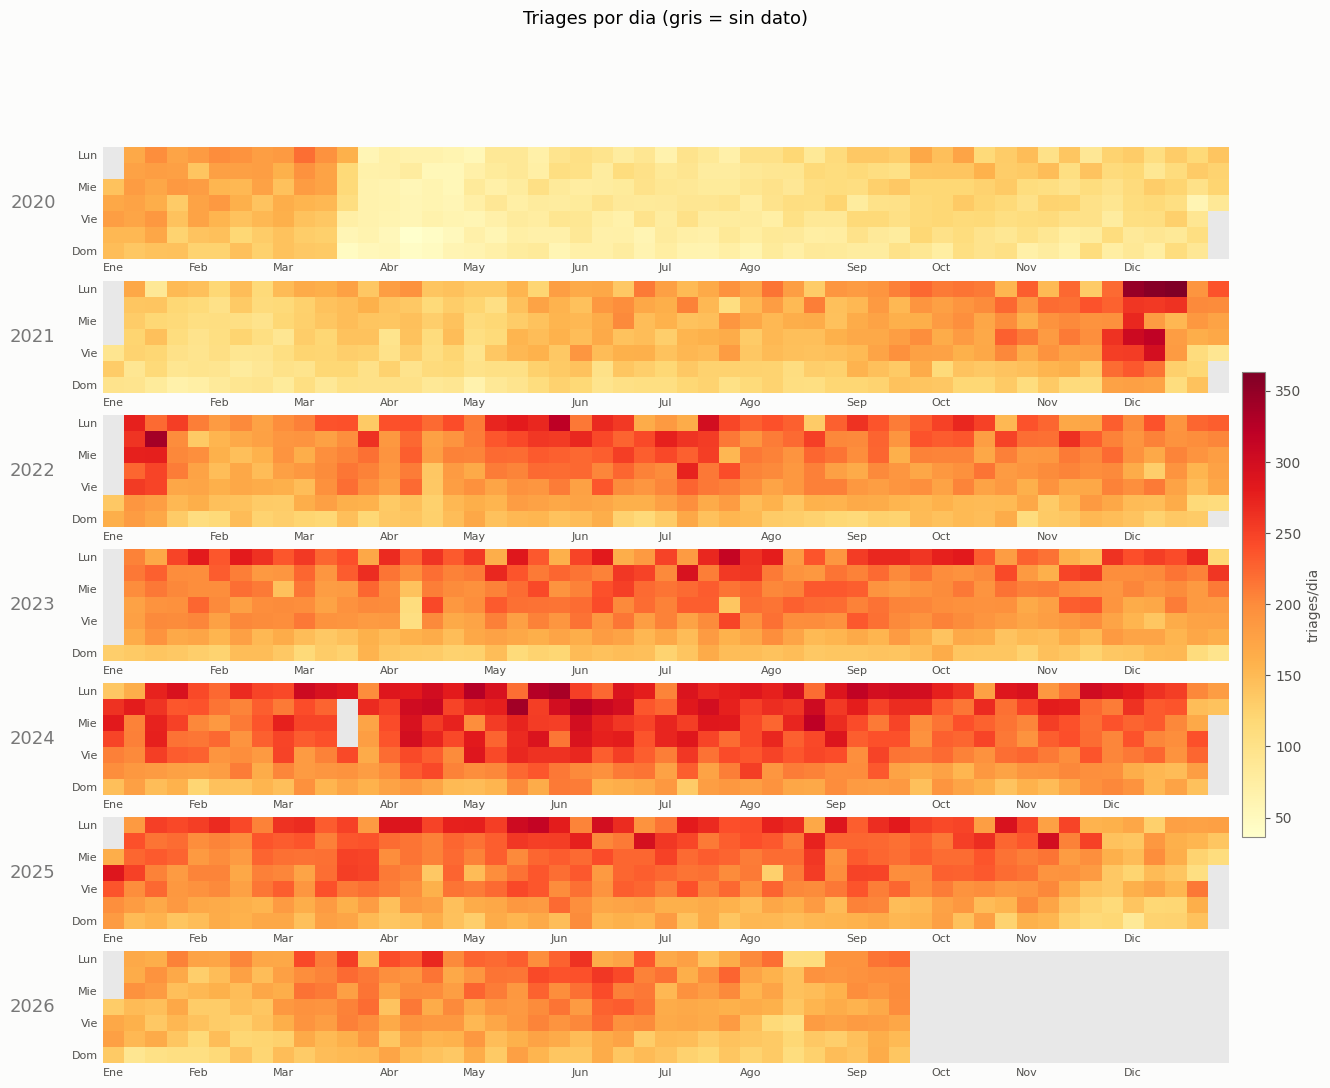

dias en gris (nulos) en la figura: ['2024-03-19', '2024-03-20', '2024-03-21']


In [5]:
fig = figuras.calendario(serie, titulo="Triages por dia (gris = sin dato)", etiqueta="triages/dia")
plt.show()
print("dias en gris (nulos) en la figura:", [f"{d:%Y-%m-%d}" for d in serie.index[serie.isna()]])

## Lectura

El calendario muestra tres cosas que la media anual esconde:

- **El bloque claro de 2020**, de marzo a julio, es el confinamiento.
- **La trama vertical constante**: son los domingos. El ciclo semanal es tan regular que se
  ve a simple vista en los siete años.
- **El apagado progresivo de 2025-2026**, que no es un escalón sino un desvanecimiento.

> **Corrección del 2026-09-29.** «No es un escalón sino un desvanecimiento» → **son dos
> escalones**, y los dos de Nueva EPS: a mediados de noviembre de 2025 (de ~125 a ~55 triages
> por día de esa EPS) y a comienzos de julio de 2026 (de ~95 a ~50), con una recuperación
> parcial en marzo de 2026 entre medias. En el calendario se ven difuminados porque el resto
> de aseguradores no cae. Sección 4.2.

Ningún día aparece en gris: **no hay huecos de registro** en los 2.454 días.

> **Corrección del 2026-09-29.** «No hay huecos de registro» es **falso**. El **19 y el 20 de
> marzo de 2024 no tienen ninguna fila**, y el **21 tiene solo 40** (el 17 % de lo esperado;
> sección 0). Es una caída del registro: urgencias no cierra. El código de la figura nunca
> rellenó con cero (`datos.serie_diaria` ya dejaba los días sin filas como nulo), así que los
> dos días sí estaban en gris; la lectura no los vio porque son dos casillas de una rejilla de
> 2.455. Ahora el 21 también es nulo, y la figura muestra **tres días en gris seguidos en la
> tercera semana de marzo de 2024** (salida de la celda). «2.454 días» eran los días con
> filas hasta el 21-sep-2026, no días sin huecos.

### Límites
El color satura en los extremos: un día de 250 y uno de 300 se ven parecidos. Para comparar
niveles sirve la figura 1.1; esta sirve para ver formas y huecos.

---
# 2. El ritmo — la hora manda sobre el día de la semana

## 2.1 Hora × día de la semana

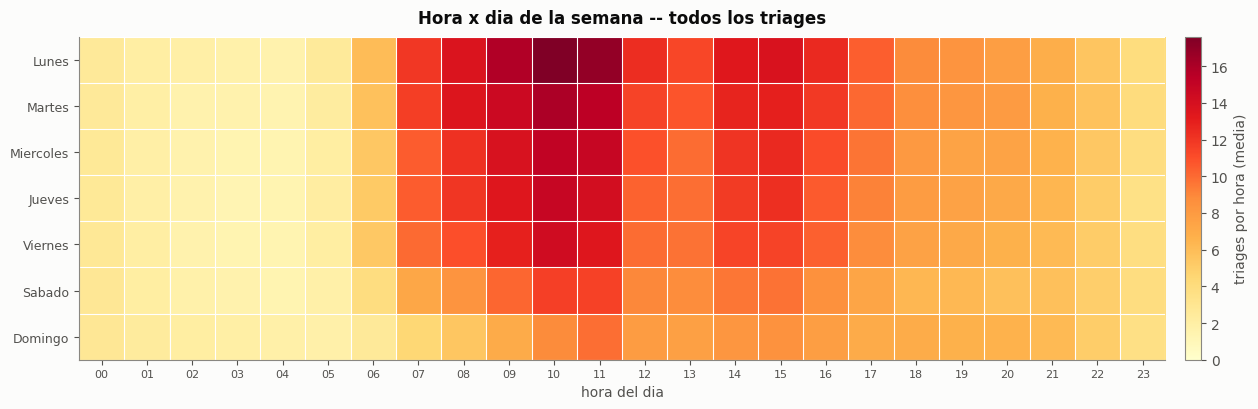

pico  Lunes 10h -> 17.6 triages/h
valle Jueves 03h -> 1.3 triages/h
oscilacion hora x dia : 13.9x
oscilacion semanal    : 1.57x  (Lunes 208.8 -> Domingo 132.7)


In [6]:
fig = figuras.reloj_semanal(total)
plt.show()

nd = total.drop_duplicates("dia").groupby("dow")["dia"].nunique()
med = total.pivot_table(index="dow", columns="hora", values="n", aggfunc="sum").div(nd, axis=0)
i = np.unravel_index(np.nanargmax(med.to_numpy()), med.shape)
j = np.unravel_index(np.nanargmin(med.to_numpy()), med.shape)
print(f"pico  {datos.DIAS[med.index[i[0]]]} {med.columns[i[1]]:02d}h -> {med.to_numpy()[i]:.1f} triages/h")
print(f"valle {datos.DIAS[med.index[j[0]]]} {med.columns[j[1]]:02d}h -> {med.to_numpy()[j]:.1f} triages/h")
print(f"oscilacion hora x dia : {med.to_numpy()[i]/med.to_numpy()[j]:.1f}x")

pd_ = serie.groupby(serie.index.dayofweek).mean()
print(f"oscilacion semanal    : {pd_.max()/pd_.min():.2f}x  "
      f"({datos.DIAS[pd_.idxmax()]} {pd_.max():.1f} -> {datos.DIAS[pd_.idxmin()]} {pd_.min():.1f})")

## Lectura

**El pico es el lunes a las 10 con 17,6 triages/hora. El valle es el jueves a las 3 con
1,3. Eso es 13,9× de oscilación** — contra 1,57× entre lunes y domingo.

> **La hora es casi nueve veces más informativa que el día de la semana**, y hasta este
> cuaderno no había ninguna figura que lo mostrara.

Tiene una consecuencia directa de diseño: cualquier control de calendario que use solo el
día de la semana está dejando fuera la variable que más manda.

### Límites
- «Nueve veces más informativa» es la razón de las dos oscilaciones (13,9 / 1,57), no una
  medida de información. Para un pronóstico **diario** la hora no entra; entra para uno horario.
- Al quitar el 21-sep-2026 incompleto, la media del lunes pasa de 208,5 a 208,8 (salida de
  la celda); la oscilación semanal sigue en 1,57×.

## 2.2 La forma del día

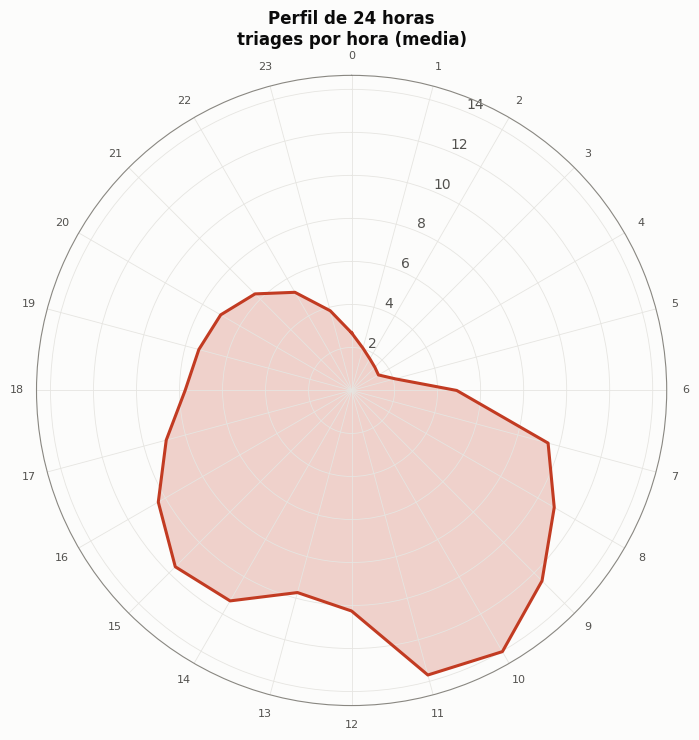

Cuota de la madrugada (00-05h) dentro del dia:
  Lunes       5.84%
  Martes      5.64%
  Miercoles   5.80%
  Jueves      5.94%
  Viernes     6.30%
  Sabado      7.52%
  Domingo     9.61%

domingo / jueves = 1.62x   (sin interaccion seria 1,00)
varianza que explica el modelo aditivo (dia + hora): 97.30%
residuo maximo: 1.69x

Cuota de cada hora en el dia medio (%), para ubicar las jorobas:
  06h  2.8  07h  5.4  08h  6.2  09h  7.1  10h  7.9  11h  7.8  12h  5.8  13h  5.5  14h  6.4  15h  6.6  16h  5.9  17h  5.1  18h  4.4  19h  4.2  20h  4.0  21h  3.6  22h  3.0  23h  2.2


In [7]:
fig = figuras.polar(total)
plt.show()

forma = med.div(med.sum(axis=1), axis=0)
mad = forma.loc[:, 0:5].sum(axis=1)
print("Cuota de la madrugada (00-05h) dentro del dia:")
for d in range(7):
    print(f"  {datos.DIAS[d]:<10} {100*mad[d]:5.2f}%")
print(f"\ndomingo / jueves = {mad[6]/mad[3]:.2f}x   (sin interaccion seria 1,00)")

L = np.log(med.to_numpy())
aditivo = L.mean() + (L.mean(axis=1) - L.mean())[:, None] + (L.mean(axis=0) - L.mean())[None, :]
resid = L - aditivo
print(f"varianza que explica el modelo aditivo (dia + hora): {100*(1-resid.var()/L.var()):.2f}%")
print(f"residuo maximo: {np.exp(np.abs(resid).max()):.2f}x")

perfil = 100 * med.mean() / med.mean().sum()
print("\nCuota de cada hora en el dia medio (%), para ubicar las jorobas:")
print("  " + "  ".join(f"{h:02d}h {v:4.1f}" for h, v in perfil.items() if h >= 6))

## Lectura

**El día tiene dos jorobas**, no una: pico a las 10-11, **valle a las 13-14**, segundo pico
a las 18-19, colapso entre las 2 y las 5.

> **Corrección del 2026-09-29.** Las horas de la segunda joroba estaban mal → el perfil
> medido (última salida de la celda) tiene el pico a las **10-11 h** (7,9 y 7,8 % del día), el
> valle a las **12-13 h** (5,8 y 5,5 %) y el **segundo pico a las 14-15 h** (6,4 y 6,6 %).
> Desde las 16 h la curva solo baja: a las 18-19 h está en 4,4 y 4,2 %. El colapso es a las
> 2-4 h (0,8-1,0 %). Las dos jorobas existen; la segunda es de primera hora de la tarde, no
> de la noche.

Eso no es un detalle estético. Si el ciclo diario se modela con ondas (Fourier), **un solo
armónico de 24 h dibuja una sola joroba**. Harán falta dos o tres. Ahora se sabe por qué, y
no por tanteo.

**Y hay interacción entre la hora y el día de la semana.** El modelo aditivo explica el
97,30 % de la rejilla — casi todo — pero el residuo máximo es 1,69× y no está repartido al
azar:

| | Cuota de la madrugada |
|---|---|
| Jueves | 5,94 % |
| Sábado | 7,52 % |
| **Domingo** | **9,61 %** |

**Domingo / jueves = 1,62×.** El fin de semana no solo tiene menos volumen: **tiene otra
forma**.

Es la primera señal, sin haber clasificado una sola nota, de que **lo que se consulta
cambia con el momento**. Una mañana de lunes y una madrugada de domingo no traen a la misma
gente. La sección 3 lo confirma por otra vía.

### Límites
Es el promedio de seis años y medio. Si la forma del día cambió en algún momento (por
ejemplo, con un cambio de turnos), este promedio lo mezcla.

---
# 3. Qué tipo de hospital es este

El nivel de urgencia (`HCNCLAURGTR`) está **al 100 % en los 433.620 registros desde 2020**.
No depende del texto ni de ningún modelo: es una clasificación que hace el personal en el
momento del triage.

> **Corrección del 2026-09-29.** Los 433.620 registros llegaban a un 22-sep-2026 parcial →
> con el corte común de este cuaderno (hasta el 20-sep y sin la caída del 21-mar-2024) son
> **433.258** (salida de la celda). El 100 % de cobertura no cambia.

In [8]:
print(f"registros con nivel: {nivel['n'].sum():,}")
resumen = (nivel.groupby(["nivel", "nivel_nombre"])["n"].sum()
           .sort_values(ascending=False).reset_index())
resumen["cuota"] = 100 * resumen["n"] / resumen["n"].sum()
print(f"{'nivel':<8}{'descripcion':<42}{'n':>10}{'cuota':>8}")
for _, r in resumen.head(10).iterrows():
    print(f"{r.nivel:<8}{str(r.nivel_nombre)[:40]:<42}{r.n:>10,}{r.cuota:>7.1f}%")

GRUPO = {"I": "urgente", "II": "urgente", "I-G": "urgente", "II-G": "urgente",
         "IIIU": "urgencia", "III": "diferido", "III-G": "diferido",
         "IV": "no urgente", "IV-G": "no urgente",
         "V": "consulta externa", "V-G": "consulta externa"}
nivel["grupo"] = nivel["nivel"].map(GRUPO).fillna("otro")
g = nivel.groupby("grupo")["n"].sum()
g = 100 * g / g.sum()
print(f"\n  urgencia real (I, II)     {g.get('urgente', 0):5.1f}%")
print(f"  urgencia (IIIU)           {g.get('urgencia', 0):5.1f}%")
print(f"  diferido (III)            {g.get('diferido', 0):5.1f}%")
print(f"  NO urgente (IV) + externa {g.get('no urgente', 0) + g.get('consulta externa', 0):5.1f}%")

n_niv = nivel.groupby("nivel")["n"].sum(); N = n_niv.sum()
print(f"\n  solo IV + V               {100*(n_niv['IV'] + n_niv['V'])/N:5.1f}%")
print(f"  emergencia I + I-G        {n_niv['I'] + n_niv['I-G']:,} casos ({n_niv['I']:,} + {n_niv['I-G']:,}) = {100*(n_niv['I'] + n_niv['I-G'])/N:.2f}%")
print(f"  obstetrico (sufijo -G)    {100*n_niv[[k for k in n_niv.index if k.endswith('-G')]].sum()/N:5.1f}%")

registros con nivel: 433,258
nivel   descripcion                                        n   cuota
IV      DIFERIDA/NO URGENTE                          169,651   39.2%
IIIU    URGENCIA                                     106,550   24.6%
V       CONSULTA EXTERNA                              52,986   12.2%
III-G   URGENCIA OBSTETRICA DIFERIDA O MENOR          47,285   10.9%
III     DIFERIDA                                      41,693    9.6%
II      URGENCIA MEDICA                                6,477    1.5%
II-G    URGENCIA MEDICA OBSTETRICA                     6,296    1.5%
I       EMERGENCIA                                     1,460    0.3%
M       MUERTO                                           285    0.1%
IV-G    NO URGENTE OBSTETRICA                            265    0.1%

  urgencia real (I, II)       3.3%
  urgencia (IIIU)            24.6%
  diferido (III)             20.5%
  NO urgente (IV) + externa  51.5%

  solo IV + V                51.4%
  emergencia I + I-G        1,591 c

## Lectura

| Nivel | Qué es | Cuota |
|---|---|---|
| IV | Diferida / no urgente | **39,2 %** |
| IIIU | Urgencia | 24,6 % |
| V | Consulta externa | 12,2 % |
| III-G | Urgencia obstétrica diferida | 10,9 % |
| III | Diferida | 9,6 % |
| II + II-G | Urgencia médica | 3,0 % |
| **I + I-G** | **Emergencia** | **0,4 %** |

> **Más de la mitad de los triages de este hospital son no urgentes (IV + V = 51,4 %).
> Las emergencias reales son el 0,4 %: 1.463 casos en seis años y medio.**

> **Corrección del 2026-09-29.** «1.463 casos» es solo el nivel I → las emergencias I + I-G
> son **1.591** (1.460 + 131 con el corte común), el 0,37 % (salida de la celda). El obstétrico (sufijo `-G`) da
> **12,5 %**, no 12,6 %.

Esto contesta la pregunta de qué tipo de servicio es, y **sostiene el mecanismo que el
proyecto quiere medir**. La hipótesis de partida era:

> *«a la gente le empieza a dar gripa, y las personas con gripa van al hospital, o por lo
> menos a que les generen la incapacidad del día por el triage»*

> **Corrección del 2026-09-29.** Se presentó la gripa como «la hipótesis de partida» del
> proyecto → el propietario aclaró el 28-09 que era **un ejemplo del tipo de razonamiento**
> («factor externo → cambio en la demanda»), no la hipótesis a perseguir. El desenlace es el
> **triage total** y no la gripa ni los niños (`CLAUDE.md`; `docs/CONTEXTO.md`, «Corrección del
> propietario: el ejemplo de la gripa no es el objetivo»). Lo que sí sigue en pie: un servicio
> con la mitad de consultas no urgentes es uno donde la demanda **puede** moverse por
> factores externos (la incapacidad, un evento, una EPS), porque no es solo trauma grave.

Un servicio donde la mitad de las consultas son no urgentes es exactamente donde ese
comportamiento es posible. Si el 90 % fueran emergencias, la hipótesis sería poco creíble.

**Hay además un componente obstétrico grande**: los niveles con sufijo `-G` suman un
12,6 %. Esa población no responde al clima igual que el resto, y conviene poder separarla.

### Límites

El nivel lo asigna una persona con un criterio, y **ese criterio cambió**. Es la sección
siguiente, y obliga a releer todo lo anterior. Además, el nivel mide lo que el hospital
decide hacer con el paciente, no la gravedad (cuaderno 02, sección 3).

---
# 4. La caída no es lo que parece

La sección 1 dejó abierta la pregunta: **¿por qué cayó el volumen un 23,9 % desde 2024?**
Si la caída fuera de demanda, debería repartirse por igual entre los niveles de urgencia.
Si fuera de clasificación, se concentraría.

> **Corrección del 2026-09-29.** El planteamiento de esta sección mezcla dos preguntas. Cómo
> se reparte la caída **entre niveles** dice si cambió el criterio (sí cambió), pero **no**
> dice si la caída del conteo es real: reetiquetar no quita ni pone pacientes. La pregunta
> «¿por qué cayó el volumen?» se contesta con otra variable, el asegurador (sección 4.2).

## 4.1 La composición por nivel

In [9]:
anual = nivel.assign(anio=nivel["dia"].dt.year).pivot_table(
    index="anio", columns="grupo", values="n", aggfunc="sum").fillna(0)
orden = ["urgente", "urgencia", "diferido", "no urgente", "consulta externa"]
anual = anual[[c for c in orden if c in anual.columns]]

print("CUOTA POR ANIO (%)")
print((100 * anual.div(anual.sum(axis=1), axis=0)).round(1).to_string())

dias_2026 = nivel.loc[nivel["dia"].dt.year == 2026, "dia"].nunique()
print(f"\nCAMBIO 2024 -> 2026 (2026 anualizado con {dias_2026} dias)")
a, b = anual.loc[2024], anual.loc[2026] * 365 / dias_2026
for c in anual.columns:
    print(f"  {c:<18}{a[c]:>9,.0f} ->{b[c]:>9,.0f}   {100*(b[c]/a[c]-1):+7.1f}%")
print(f"  {'TOTAL':<18}{a.sum():>9,.0f} ->{b.sum():>9,.0f}   {100*(b.sum()/a.sum()-1):+7.1f}%")

mes_total = nivel.assign(ym=nivel["dia"].dt.to_period("M")).groupby("ym")["n"].sum()
print("\ntriages por mes, sep-2025 a ene-2026:", {str(k): int(v) for k, v in mes_total.loc["2025-09":"2026-01"].items()})

CUOTA POR ANIO (%)
grupo  urgente  urgencia  diferido  no urgente  consulta externa
anio                                                            
2020       5.9      34.9      23.6        19.4              16.2
2021       3.9      29.0      20.9        35.2              10.9
2022       3.1      24.4      14.8        45.5              12.2
2023       2.3      25.4      15.4        46.5              10.4
2024       1.9      21.2      14.3        48.4              14.1
2025       3.3      21.5      25.4        37.2              12.6
2026       4.8      20.9      37.7        26.9               9.7

CAMBIO 2024 -> 2026 (2026 anualizado con 263 dias)
  urgente               1,600 ->    3,020     +88.7%
  urgencia             17,450 ->   13,147     -24.7%
  diferido             11,809 ->   23,726    +100.9%
  no urgente           39,850 ->   16,944     -57.5%
  consulta externa     11,599 ->    6,125     -47.2%
  TOTAL                82,308 ->   62,962     -23.5%

triages por mes, sep-2025

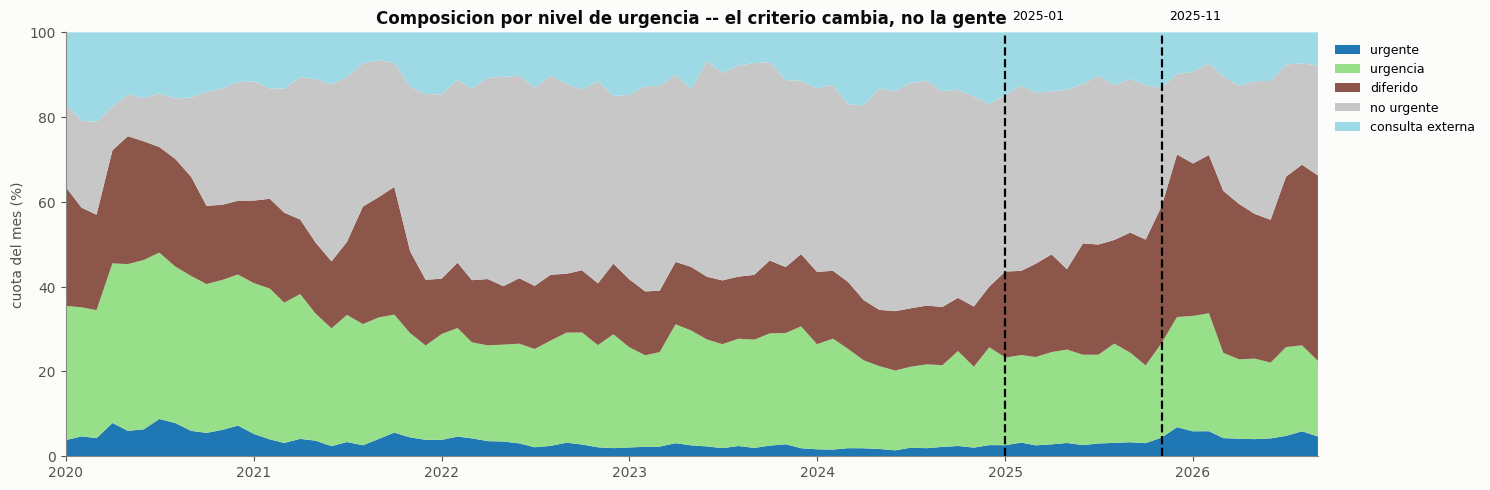

In [10]:
mensual = nivel.assign(ym=nivel["dia"].dt.to_period("M")).pivot_table(
    index="ym", columns="grupo", values="n", aggfunc="sum").fillna(0)
mensual = mensual[[c for c in orden if c in mensual.columns]]
cuota = 100 * mensual.div(mensual.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(15, 5))
ax.stackplot(cuota.index.to_timestamp(), cuota.to_numpy().T, labels=cuota.columns,
             colors=plt.get_cmap("tab20")(np.linspace(0, 1, cuota.shape[1])))
ax.axvline(pd.Timestamp("2025-01-01"), color="black", lw=1.6, ls="--")
ax.axvline(pd.Timestamp("2025-11-01"), color="black", lw=1.6, ls="--")
ax.text(pd.Timestamp("2025-01-15"), 103, "2025-01", fontsize=9)
ax.text(pd.Timestamp("2025-11-15"), 103, "2025-11", fontsize=9)
ax.set_ylim(0, 100); ax.set_xlim(cuota.index.to_timestamp().min(), cuota.index.to_timestamp().max())
ax.set_ylabel("cuota del mes (%)")
ax.set_title("Composicion por nivel de urgencia -- el criterio cambia, no la gente", fontsize=12)
ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1), fontsize=9, frameon=False)
plt.tight_layout(); plt.show()

## Lectura — este es el hallazgo principal del cuaderno

**La caída no se reparte. Se concentra, y en direcciones opuestas.**

| Grupo | 2024 → 2026 |
|---|---|
| Diferido (III) | **+101,5 %** |
| Urgente (I, II) | **+89,0 %** |
| Urgencia (IIIU) | −24,4 % |
| **No urgente (IV)** | **−57,4 %** |
| Consulta externa (V) | −47,1 % |
| **TOTAL** | **−23,3 %** |

> **Corrección del 2026-09-29.** Con el corte común (2026 hasta el 20-sep, 263 días, y sin la
> caída del 21-mar-2024), las cifras de la salida son: diferido **+100,9 %**, urgente
> **+88,7 %**, urgencia −24,7 %, no urgente −57,5 %, consulta externa −47,2 %, total
> **−23,5 %**. La forma no cambia.

La cuota de «no urgente» pasó del **48,4 % en 2024 al 26,9 % en 2026**, mientras «diferido»
subía del 14,3 % al 37,7 %. Y «urgente» se duplicó.

> **Las emergencias reales no se duplican en dos años. Lo que cambió es dónde se pone la
> raya.** Es una deriva del criterio de triage, no un cambio en quién llega.

**Cuándo pasó**: no es un escalón, es una deriva progresiva que arranca en **enero de 2025**
y se acelera en **noviembre-diciembre de 2025**, donde además cae el volumen total de golpe
(6.431 → 5.161 → 4.572 triages/mes).

> **Corrección del 2026-09-29.** Los triages por mes, rehechos con el `triage_nivel` actual,
> son **6.434 → 5.165 → 4.581** (octubre, noviembre y diciembre de 2025; salida de la celda).
> Y «un cambio en quién llega» **sí** ocurrió en noviembre de 2025: es cuando Nueva EPS se
> desploma en el SES (sección 4.2). La deriva de enero a octubre de 2025 es otra cosa, porque
> pasa con la cuota de Nueva EPS estable.

## Cuatro consecuencias, y ninguna es menor

1. **La caída del 23,9 % es en parte artefacto.** Hay menos demanda real, pero mucho menos
   del 23,9 %. Un modelo entrenado sobre el total 2024-2026 está modelando un cambio de
   criterio administrativo.

> **Corrección del 2026-09-29.** **Error de razonamiento.** Que los niveles se repartan de
> otra forma no dice nada del conteo: un paciente reetiquetado de IV a III sigue siendo un
> triage. La caída del 23,9 % **no es artefacto**: es demanda que dejó de llegar, y es de
> **Nueva EPS** (sección 4.2). Lo que un modelo del total 2024-2026 modela sin saberlo no es
> un cambio de criterio, es **el estado de la relación entre el SES y Nueva EPS**.

2. **El nivel de urgencia no es comparable a lo largo del tiempo.** Sirve para caracterizar
   el hospital (sección 3) y para separar poblaciones dentro de un periodo corto, pero un
   «triage IV» de 2024 y uno de 2026 no son lo mismo.
3. **La ventana con texto es justo la ventana contaminada.** `HCTMOTCON` existe desde 2025,
   que es exactamente cuando empieza la deriva. Cualquier serie por motivo cae encima de
   este cambio.
4. **Hay que auditar el resto de variables igual.** Si una columna central tiene una deriva
   no documentada, no hay razón para suponer que las demás no la tengan. La sección 5
   encuentra la segunda.

### Límites
La composición por nivel usa colores `tab20` de la versión original; no es la paleta de los
cuadernos nuevos. La figura se deja como estaba porque es la que se leyó el 22-09.

## 4.2 Quién explica la caída del volumen: Nueva EPS

*Sección añadida el 2026-09-29.* Con la entidad administradora (`DIM_TRIAGE.GEENENTADM` →
`DIM_ENTIDAD`, extraída el 28-09 con `python -m extraccion --entidad` y agrupada con
`extraccion.entidades.clasificar`) se puede partir el conteo por quién paga. Se compara
**Nueva EPS** contra **todo lo demás** (EPS Sura, otras EPS, SOAT, ARL, particulares…).

**Contexto que aporta el propietario** (`docs/CONTEXTO.md`, «Dos capas»): la Supersalud
intervino Nueva EPS por corrupción el **3 de abril de 2024**; quedó al borde de la quiebra y
no puede pagar los tratamientos, y sus afiliados dejaron de venir porque saben que no los van
a atender.

In [11]:
g = entidad.pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").reindex(dias).fillna(0)
nueva = g["nueva_eps"].where(serie.notna())
resto = serie - nueva
sura  = g["sura_eps"].where(serie.notna())

A = pd.DataFrame({"total": serie, "Nueva EPS": nueva, "resto": resto, "de ello Sura": sura})
tabla = A.groupby(A.index.year).mean()
tabla["% Nueva EPS"] = 100 * tabla["Nueva EPS"] / tabla["total"]
print("TRIAGES POR DIA, MEDIA DEL ANIO")
print(tabla.round(1).to_string())

print("\nDE DONDE SALE CADA CAMBIO (triages por dia)")
for a0, a1 in [(2024, 2025), (2025, 2026), (2024, 2026)]:
    d = tabla.loc[a1] - tabla.loc[a0]
    print(f"  {a0} -> {a1}: total {d.total:+6.1f}   Nueva EPS {d['Nueva EPS']:+6.1f}   resto {d.resto:+6.1f}")

sem = A[["Nueva EPS", "resto"]].resample("W-SAT").mean()
print("\nNueva EPS por semana alrededor de los dos desplomes (triages/dia, semana que termina en):")
for a0, a1 in [("2025-10-25", "2025-12-13"), ("2026-06-06", "2026-07-25")]:
    print("  " + "  ".join(f"{d:%d-%b-%y} {v:5.1f}" for d, v in sem.loc[a0:a1, "Nueva EPS"].items()))

TRIAGES POR DIA, MEDIA DEL ANIO
      total  Nueva EPS  resto  de ello Sura  % Nueva EPS
2020  105.7       64.8   40.9           8.6         61.3
2021  149.3       86.1   63.3          16.8         57.6
2022  189.6      125.3   64.3          28.5         66.1
2023  192.4      122.9   69.5          41.1         63.9
2024  226.9      125.6  101.3          69.6         55.4
2025  199.6      115.8   83.8          53.9         58.0
2026  172.6       72.2  100.4          62.0         41.8

DE DONDE SALE CADA CAMBIO (triages por dia)
  2024 -> 2025: total  -27.2   Nueva EPS   -9.8   resto  -17.4
  2025 -> 2026: total  -27.0   Nueva EPS  -43.6   resto  +16.6
  2024 -> 2026: total  -54.2   Nueva EPS  -53.4   resto   -0.9

Nueva EPS por semana alrededor de los dos desplomes (triages/dia, semana que termina en):
  25-Oct-25 136.0  01-Nov-25 125.6  08-Nov-25 116.9  15-Nov-25 105.4  22-Nov-25  85.9  29-Nov-25  59.3  06-Dec-25  54.7  13-Dec-25  61.7
  06-Jun-26  98.9  13-Jun-26 100.9  20-Jun-26  98.

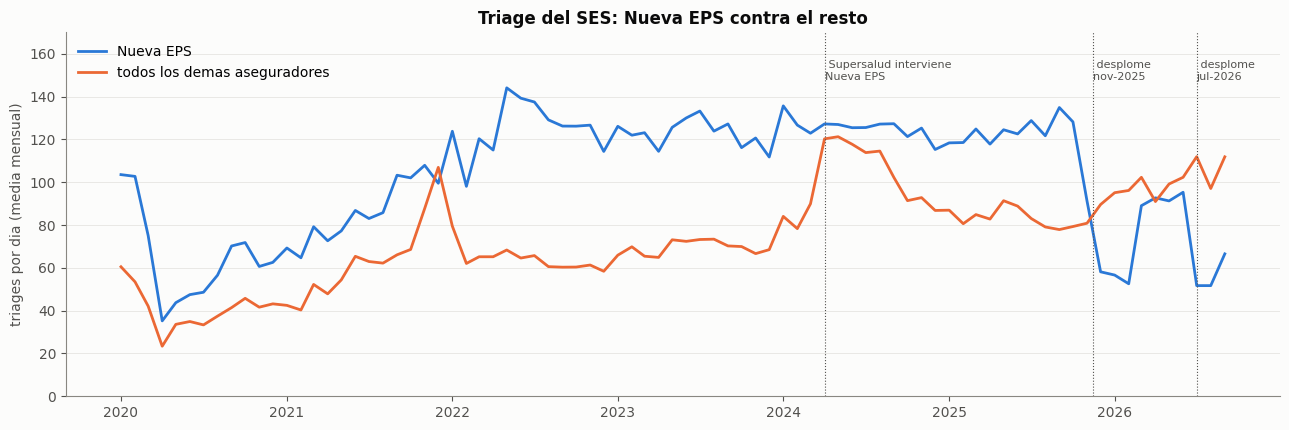

In [12]:
M = A[["Nueva EPS", "resto"]].resample("MS").mean()
fig, ax = plt.subplots(figsize=(13, 4.4))
ax.plot(M.index, M["Nueva EPS"], color=AZUL, lw=2, label="Nueva EPS")
ax.plot(M.index, M["resto"], color=NARANJA, lw=2, label="todos los demas aseguradores")
tope = M.max().max()
for f, t in [("2024-04-03", "Supersalud interviene\nNueva EPS"), ("2025-11-15", "desplome\nnov-2025"),
             ("2026-07-01", "desplome\njul-2026")]:
    ax.axvline(pd.Timestamp(f), color=TINTA2, lw=.8, ls=":")
    ax.text(pd.Timestamp(f), tope * 1.02, " " + t, fontsize=8, color=TINTA2, va="bottom")
ax.set_ylim(0, tope * 1.18); ax.grid(axis="y")
ax.set_ylabel("triages por dia (media mensual)")
ax.set_title("Triage del SES: Nueva EPS contra el resto")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## Lectura

**La caída desde 2024 es, casi entera, de Nueva EPS.** Triages por día (salida de la celda):

| | 2024 | 2025 | 2026 |
|---|---|---|---|
| Total | 226,9 | 199,6 | 172,6 |
| **Nueva EPS** | 125,6 | 115,8 | **72,2** |
| Todos los demás | 101,3 | 83,8 | 100,4 |
| % Nueva EPS | 55,4 | 58,0 | **41,8** |

- **De 2024 a 2026 el total pierde 54,2 triages por día y Nueva EPS pierde 53,4.** El resto
  de aseguradores queda prácticamente igual (−0,9).
- **Pero los dos tramos son distintos**, y eso no estaba dicho en ningún sitio:
  - **2024 → 2025** (−27,2): la mayor parte es del resto (−17,4), sobre todo de EPS Sura
    (69,6 → 53,9). Sura había saltado en abril de 2024, justo cuando la Supersalud intervino
    Nueva EPS (se ve en la figura como un escalón del resto), y fue bajando después. El pico
    de 2024 es en parte ese salto.
  - **2025 → 2026** (−27,0): Nueva EPS pierde 43,6 triages por día, y el resto **sube**
    16,6, sin compensarlo.
- **Los cambios de Nueva EPS son escalones, no una pendiente.** Estable en ~120-135 por día
  hasta octubre de 2025; cae **en la segunda quincena de noviembre de 2025** hasta ~55; se
  recupera en **marzo de 2026** a ~90-100; y vuelve a caer **la primera semana de julio de
  2026** a ~50.
- El desplome de noviembre **empieza antes del 1 de diciembre**, fecha del cierre de Santa
  Sofía a Nueva EPS, así que apunta a algo entre el SES y Nueva EPS (cuaderno 07, sección 5).

**Consecuencia.** El total del SES tiene dos capas con causas distintas (`CONTEXTO.md`,
«Dos capas»): **el nivel**, que lo mueve la red de salud en escalones que duran meses, y
**los picos**, que los mueven otras cosas. Un pronóstico que no lleve el estado de Nueva EPS
atribuirá esos escalones a cualquier variable que tenga tendencia.

### Límites
- La clasificación de entidades es un **borrador** que revisa el propietario
  (`salidas/entidades_clasificadas.csv`).
- Las fechas exactas de suspensión y reanudación de servicios entre el SES y Nueva EPS **no
  están en la base**; los escalones se leen de la serie. Solo el propietario puede
  conseguirlas.
- Esto dice **quién** dejó de venir, no **por qué**. La intervención de la Supersalud es
  contexto del propietario, no algo medido aquí.

### ¿Y la reclasificación? Otro fenómeno, con un acople parcial

Si la caída del volumen es de Nueva EPS, ¿qué pasa con el cambio de criterio? Se compara, mes
a mes, la cuota de Nueva EPS con la cuota de «no urgente» (IV y IV-G). No hay cruce nivel ×
entidad en los datos, así que esto es una comparación de dos series, no un desglose.

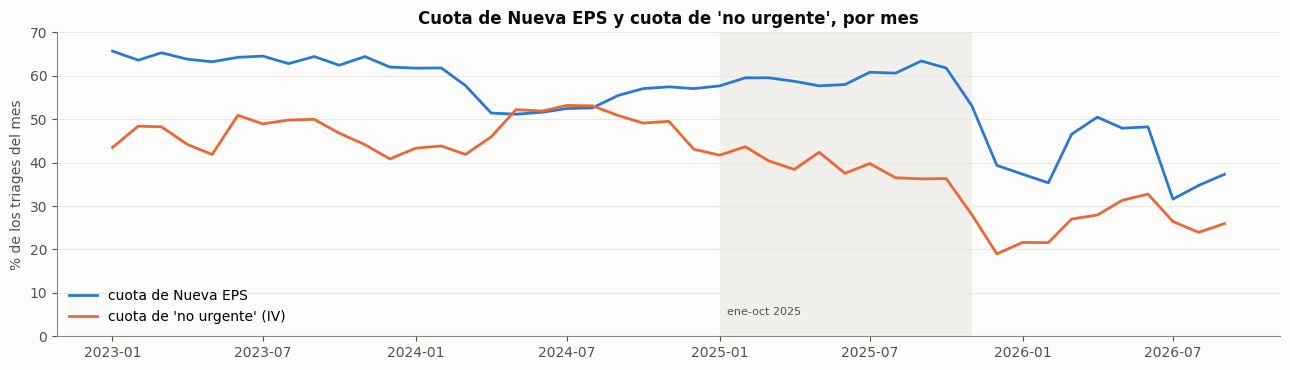

medias por tramo:
  2024                   {'% Nueva EPS': 55.6, '% no urgente': 48.1}
  ene-oct 2025           {'% Nueva EPS': 59.8, '% no urgente': 39.3}
  dic-2025 a feb-2026    {'% Nueva EPS': 37.3, '% no urgente': 20.7}
  mar-jun 2026           {'% Nueva EPS': 48.3, '% no urgente': 29.7}
  jul-sep 2026           {'% Nueva EPS': 34.5, '% no urgente': 25.4}

correlacion mensual entre las dos cuotas: nov-2025 a sep-2026 r = +0.63 (11 meses);  ene-2024 a oct-2025 r = -0.80


In [13]:
ne_mes = (entidad.assign(ym=entidad["dia"].dt.to_period("M"), ne=np.where(entidad["grupo"] == "nueva_eps", entidad["n"], 0))
                 .groupby("ym")[["ne", "n"]].sum())
comp = pd.DataFrame({"% Nueva EPS": 100 * ne_mes["ne"] / ne_mes["n"],
                     "% no urgente": cuota["no urgente"]}).dropna()
comp = comp.loc["2023-01":]

fig, ax = plt.subplots(figsize=(13, 3.8))
x = comp.index.to_timestamp()
ax.plot(x, comp["% Nueva EPS"], color=AZUL, lw=2, label="cuota de Nueva EPS")
ax.plot(x, comp["% no urgente"], color=NARANJA, lw=2, label="cuota de 'no urgente' (IV)")
ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2025-10-31"), color="#f0efec", zorder=0)
ax.text(pd.Timestamp("2025-01-10"), 5, "ene-oct 2025", fontsize=8, color=TINTA2)
ax.set_ylim(0, 70); ax.set_ylabel("% de los triages del mes"); ax.grid(axis="y")
ax.set_title("Cuota de Nueva EPS y cuota de 'no urgente', por mes"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

def tramo(a0, a1):
    t = comp.loc[a0:a1]; return t.mean().round(1).to_dict()
print("medias por tramo:")
for a0, a1, nom in [("2024-01", "2024-12", "2024"), ("2025-01", "2025-10", "ene-oct 2025"),
                    ("2025-12", "2026-02", "dic-2025 a feb-2026"), ("2026-03", "2026-06", "mar-jun 2026"),
                    ("2026-07", "2026-09", "jul-sep 2026")]:
    print(f"  {nom:<22} {tramo(a0, a1)}")
r_desde = comp.loc["2025-11":].corr().iloc[0, 1]
r_antes = comp.loc["2024-01":"2025-10"].corr().iloc[0, 1]
print(f"\ncorrelacion mensual entre las dos cuotas: nov-2025 a sep-2026 r = {r_desde:+.2f} ({len(comp.loc['2025-11':])} meses);"
      f"  ene-2024 a oct-2025 r = {r_antes:+.2f}")

## Lectura

**Son dos fenómenos, y solo el segundo tramo los junta.**

- **Enero a octubre de 2025: la reclasificación va sola.** La cuota de «no urgente» baja
  del 48,1 % de 2024 al 39,3 % mientras la cuota de Nueva EPS **sube** (de 55,6 a 59,8 %). El
  cambio de criterio empezó sin que cambiara quién llega; en ese tramo las dos cuotas van
  en sentido contrario (r = −0,80 de enero de 2024 a octubre de 2025). Esa parte sigue sin explicación y
  no está en la base.
- **Desde noviembre de 2025 las dos cuotas se mueven juntas.** Cuando Nueva EPS cae
  (dic-2025 a feb-2026) «no urgente» toca su mínimo; cuando Nueva EPS se recupera (mar-jun
  2026) «no urgente» sube; cuando vuelve a caer (julio de 2026) «no urgente» baja otra vez.
  Medias por tramo: 20,7 % de «no urgente» con 37,3 % de Nueva EPS; 29,7 con 48,3; 25,4 con
  34,5. Correlación mensual de noviembre de 2025 a septiembre de 2026: **r = +0,63** (11 meses).

**Hipótesis, no conclusión:** si lo que el SES dejó de atender de Nueva EPS fue sobre todo lo
**no urgente** (lo urgente hay que atenderlo por ley), el desplome de noviembre explicaría a
la vez la caída del volumen y la aceleración de la reclasificación. Es el «solo evento» que
la versión anterior buscaba en la sección de conclusiones. **Para comprobarlo hace falta un
agregado nuevo: día × nivel × grupo de entidad**, que es una consulta de conteo con su
`GROUP BY` y se puede extraer por `extraccion/` sin dato personal.

### Límites
- Dos cuotas que se mueven juntas en once meses no son un desglose. Sin el cruce nivel ×
  entidad no se sabe qué nivel tenían los pacientes de Nueva EPS que dejaron de venir.
- La reclasificación de enero a octubre de 2025 puede tener su propia causa (directriz,
  auditoría, contrato) que solo sabe la institución.

---
# 5. La estancia — y tres regímenes de medición

`HCCFECSAL − HCCFECTUR` da el tiempo que pasa entre que el paciente entra al servicio y
sale. La cobertura es del **91,1 %** y —a diferencia del texto— **es estable en los siete
años** (85-94 %), así que no mete tendencia falsa por sí misma.

Es la variable que más se acerca a la pregunta operativa real: *¿hace falta más personal?*
Un pico de consultas que el servicio absorbe sin que suba la espera no es saturación; uno
que la sube, sí.

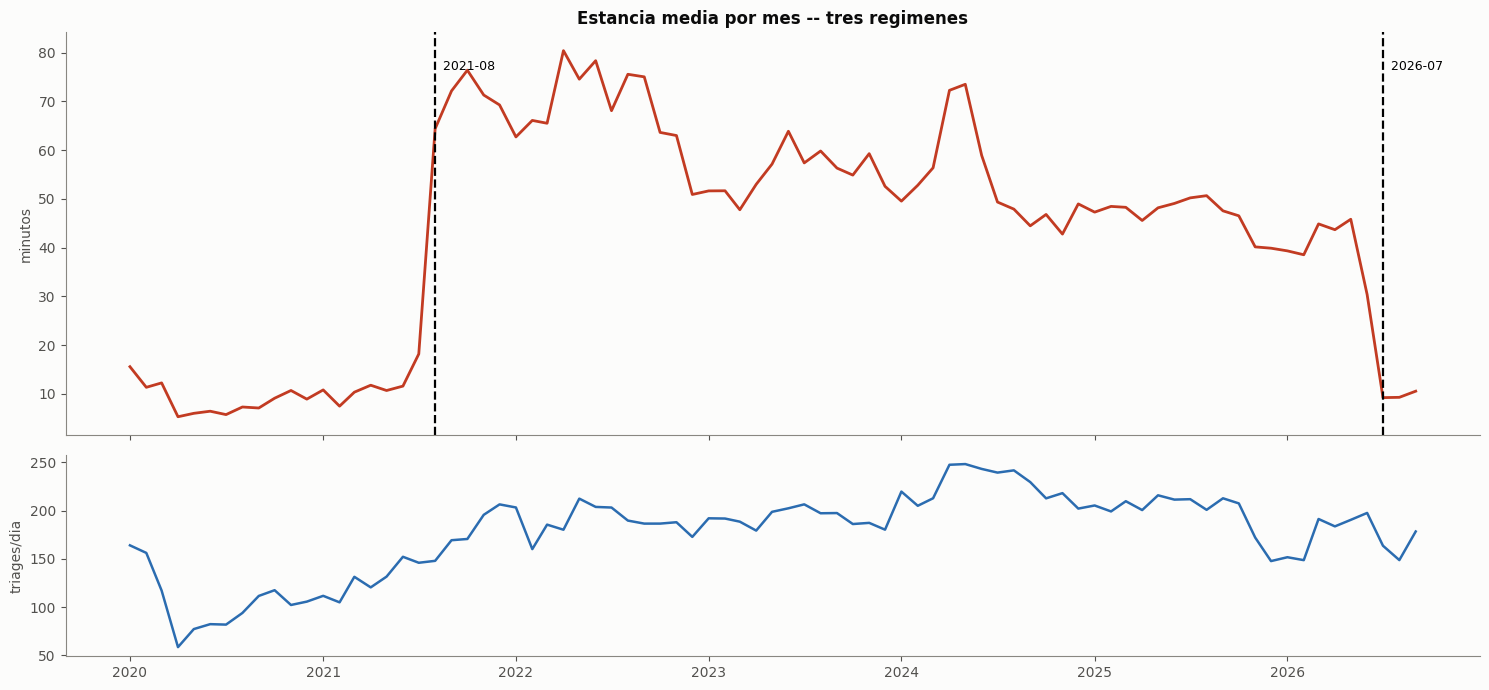

  regimen 1  2020-01 a 2021-07   estancia media   9.8 min   registros 58,211
  regimen 2  2021-08 a 2026-06   estancia media  55.8 min   registros 324,046
  regimen 3  2026-07 a 2026-09   estancia media   9.7 min   registros 12,458

cobertura por anio (%): {2020: 85.5, 2021: 93.2, 2022: 93.6, 2023: 93.1, 2024: 90.1, 2025: 90.7, 2026: 88.7}
cobertura global: 91.1 %
media anual (min): {2020: 9.8, 2021: 41.7, 2022: 68.8, 2023: 55.5, 2024: 54.0, 2025: 47.2, 2026: 30.9}


In [14]:
est = estancia.set_index("dia").sort_index()
mens = est.resample("MS").apply(lambda d: np.average(d["media_min"], weights=d["n"])
                                if len(d) else np.nan)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(mens.index, mens.to_numpy(), lw=2, color="#c23b22")
for corte, nota in [("2021-08-01", "2021-08"), ("2026-07-01", "2026-07")]:
    ax1.axvline(pd.Timestamp(corte), color="black", lw=1.6, ls="--")
    ax1.text(pd.Timestamp(corte), mens.max() * 0.95, f"  {nota}", fontsize=9)
ax1.set_ylabel("minutos"); ax1.set_title("Estancia media por mes -- tres regimenes", fontsize=12)

vol = serie.resample("MS").mean()
ax2.plot(vol.index, vol.to_numpy(), lw=1.8, color="#2b6cb0")
ax2.set_ylabel("triages/dia"); ax2.set_xlabel("")
plt.tight_layout(); plt.show()

for desde, hasta, nombre in [("2020-01", "2021-07", "regimen 1"),
                             ("2021-08", "2026-06", "regimen 2"),
                             ("2026-07", "2026-09", "regimen 3")]:
    v = mens.loc[desde:hasta]
    print(f"  {nombre}  {desde} a {hasta}   estancia media {v.mean():5.1f} min   registros {est.loc[desde:hasta, 'n'].sum():,}")

cob = est["n"].groupby(est.index.year).sum() / serie.groupby(serie.index.year).sum()
media_anual = est.groupby(est.index.year).apply(lambda d: np.average(d["media_min"], weights=d["n"]))
print("\ncobertura por anio (%):", (100 * cob).round(1).to_dict())
print(f"cobertura global: {100 * est['n'].sum() / serie.sum():.1f} %")
print("media anual (min):", media_anual.round(1).to_dict())

## Lectura

**La estancia tiene dos saltos bruscos, y ninguno es clínico.**

| Régimen | Periodo | Estancia media | Mediana |
|---|---|---|---|
| 1 | 2020-01 → 2021-07 | **9,8 min** | 3-10 min |
| 2 | 2021-08 → 2026-06 | **55,8 min** | 28-60 min |
| 3 | 2026-07 → 2026-09 | **9,9 min** | 5-6 min |

Entre julio y agosto de 2021 la mediana salta de 9 a 39 minutos — **4,3× en un mes**. Y
entre junio y julio de 2026 se desploma de 21 a 5.

> **Un servicio de urgencias no cuadruplica su tiempo de atención en un mes, ni lo divide
> por cuatro al mes siguiente. Lo que cambió es qué se graba en `HCCFECSAL`.**

## Qué queda de esto

- **La variable sirve, pero solo dentro del régimen 2**: agosto 2021 a junio 2026, que son
  casi cinco años y 300.000 registros. Es ventana de sobra.
- **Las comparaciones entre regímenes no valen.** La media anual de la sección anterior
  (9,8 min en 2020 frente a 69,5 en 2022) no mide nada real.
- **Segunda deriva no documentada encontrada en el mismo cuaderno.** Ya son dos: el criterio
  de triage y el registro de salida. Esto deja de ser una anécdota y pasa a ser un método:
  **antes de usar cualquier columna, hay que mirar su serie mensual buscando escalones.**

> **Corrección del 2026-09-29.** Cuatro precisiones, con las salidas de la celda: (1) el
> régimen 2 tiene **324.046** registros con estancia, no «300.000»; (2) no hay «sección
> anterior» con la media anual; medida aquí es **9,8 min en 2020 y 68,8 en 2022**, no 69,5;
> (3) el régimen 3 da ahora **9,7 min** y no 9,9, porque se
> quitó el 21-sep incompleto; (4) las **medianas** de la tabla (y los saltos de 9 a 39 y de 21 a 5 minutos) salieron de la
> consulta de cobertura del 22-09 y **no se pueden rehacer con `triage_estancia.parquet`**, que
> solo guarda media y máximo por día. Quedan como dato citado, no reproducido.

> **Corrección del 2026-09-29.** «Una deriva del criterio de triage» era la segunda deriva
> contada aquí; sigue siendo cierta. Pero la lista de escalones que hay que vigilar en la
> serie tiene uno más, y es el más grande: **el asegurador** (sección 4.2). No es una deriva
> de medición, es demanda real que se va y vuelve.

### Límites
Las medias diarias vienen ya recortadas a estancias entre 0 y 1.440 minutos (así las extrae
`extraccion --series`). Un cambio en cuántos registros caen fuera de ese rango también movería
la media.

---
# Conclusiones (del 2026-09-22, con sus correcciones)

## Lo que ahora se sabe

1. **La serie no crece: cayó un 23,9 % desde el pico de 2024** — pero buena parte de esa
   caída es reclasificación, no menos gente.

> **Corrección del 2026-09-29.** La reclasificación no cambia el conteo → la caída es de
> **menos gente**, y casi toda de **Nueva EPS**: de 2024 a 2026 el total pierde 54,2 triages
> por día y Nueva EPS 53,4 (sección 4.2).

2. **2020 es un cráter de COVID** (−64 % entre enero y abril) y no entra en ningún
   entrenamiento sin tratarlo aparte.
3. **La hora manda: 13,9× de oscilación contra 1,57× del día de la semana.**
4. **El día tiene dos jorobas.** Un solo armónico de 24 h no lo describe.

> **Corrección del 2026-09-29.** Las jorobas están a las 10-11 h y a las **14-15 h**, con el
> valle a las 12-13 h; no a las 18-19 h (sección 2.2).

5. **Hay interacción hora × día**: la madrugada pesa 1,62× más el domingo que el jueves. El
   fin de semana tiene otra *forma*, no solo menos volumen.
6. **Más de la mitad del hospital es no urgente** (51,4 %), y las emergencias son el 0,4 %.
   Eso sostiene el mecanismo de la incapacidad que el proyecto quiere medir.

> **Corrección del 2026-09-29.** El mecanismo de la incapacidad (y la gripa) era un
> **ejemplo** del tipo de razonamiento, no el mecanismo que el proyecto quiere medir. El
> desenlace es el triage total.

7. **Dos derivas de medición no documentadas**: el criterio de triage desde enero de 2025 y
   el registro de salida en agosto de 2021 y julio de 2026.
8. *(Añadido el 2026-09-29.)* **Hay un hueco de registro**: 19-21 de marzo de 2024. Se trata
   como nulo (sección 0).

## Lo que este cuaderno cambia en el plan

- **El control de calendario necesita la hora**, y con dos o tres armónicos, no uno.
- **La ventana de modelado útil no son los siete años.** Hay que elegirla a conciencia:
  2022-2024 es el tramo más limpio para el total; agosto 2021 - junio 2026 para la estancia.

> **Corrección del 2026-09-29.** 2022-2024 no es «limpio» para el total: en abril de 2024
> Sura salta cuando la Supersalud interviene Nueva EPS, y desde noviembre de 2025 Nueva EPS
> cae en escalones. Más que elegir una ventana, **el estado de Nueva EPS tiene que entrar en
> el modelo como variable**.

- **Auditar antes de usar** pasa a ser un paso obligatorio de cualquier variable nueva.
- **La ventana con texto (2025-2026) coincide con la deriva del criterio.** Cualquier serie
  por motivo hereda ese problema y hay que tenerlo delante al interpretarla.

## Lo que queda abierto

- **¿Por qué cambió el criterio de triage en enero de 2025?** ¿Hubo una directriz, un cambio
  de contrato, una auditoría? Es información que no está en la base.
- **¿Qué pasó en noviembre de 2025?** Cae el volumen y se acelera la reclasificación a la
  vez. Un solo evento explicaría las dos cosas.

> **Corrección del 2026-09-29.** Respondida en parte: en la segunda quincena de noviembre de
> 2025 **Nueva EPS se desploma en el SES** (sección 4.2). Queda abierto si eso explica también
> la aceleración de la reclasificación; hace falta el cruce nivel × entidad.

- **¿Qué significa `HCCFECSAL` en cada régimen?** Sin saberlo no se puede interpretar la
  estancia ni siquiera dentro del régimen 2.
- **La edad en bandas está extraída y sin mirar.** Es el siguiente cuaderno: la firma de una
  epidemia respiratoria es un pico en 0-4 y en 65+ antes que en el resto.

> **Corrección del 2026-09-29.** Ya se miró: [cuaderno 02](02_el_hospital.ipynb). Y lo
> respiratorio dejó de ser el eje (era un ejemplo).

---
# Lo que se supo después

Lo que este cuaderno no sabía el 22-09 y cambió su lectura:

- **[02 — El hospital](02_el_hospital.ipynb)** (22-09, corregido el 29-09). El nivel de triage
  mide **la decisión del hospital**, no la gravedad; por eso no sirve para comparar años. La
  edad y **la entidad administradora** son las otras dos familias de variables.
- **[05 — Validación sin motivo](05_validacion_sin_motivo.py)** (28-09; es un script, aún no un
  cuaderno). Pronóstico semanal con origen rodante: **ninguna variable externa mejoró el
  pronóstico del total** frente al control de calendario, pero lo pediátrico sí respondía al
  clima. Usaba un escalón fijo en noviembre de 2025 sin saber todavía que era Nueva EPS.
- **[06 — Patrones exploratorios](06_patrones_exploratorios.ipynb)** (28-09). Fijó la regla de
  las caídas de registro (un día sin filas es nulo; bajo el 40 % de lo esperado se excluye) y
  encontró que **7 de las 10 semanas más bajas caen entre noviembre de 2025 y febrero de
  2026**, sin que ningún calendario las explicara.
- **[07 — Mecanismos](07_mecanismos.ipynb)** (28-09). Las explicó: **Nueva EPS** pasa de 115,8 a
  72,2 triages por día entre 2025 y 2026, y su cuota del 58 % al 42 %, con desplomes en
  noviembre de 2025 y julio de 2026. Además, la Feria (SOAT +37 % contra +12 % de otros
  regresos de vacaciones) y el paso de seco a lluvioso en los niños de 0-4 años.
- **La decisión de las dos capas** (`docs/CONTEXTO.md`, 28-09): **el nivel** lo mueve la red de
  salud; **los picos**, otras cosas. Los picos se miden contra el nivel reciente, no contra la
  media del año.

> **Corrección del 2026-09-29 (clima corregido).** El paso de seco a lluvioso en 0-4 años que se
> cita del 07 (**+22,0 ± 17,8 % a los 7-13 días, 13 episodios**) se midió con un pluviómetro que
> reportaba cero de octubre de 2025 a julio de 2026 (cuaderno 03, sección 3.1). Con el clima
> corregido es **+13,4 ± 15,0 % a los 7-13 días y +10,0 ± 16,4 % a los 14-20 días (17 episodios)**:
> conserva la forma, pero **ya no se distingue de cero**. Nueva EPS y la Feria no dependen de la
> lluvia y no cambian. Este cuaderno no lee el clima: ninguna otra cifra suya se mueve.

**Lo que sigue en pie de este cuaderno:** la serie cae desde 2024; 2020 es un cráter; la hora
manda sobre el día; el día tiene dos jorobas y el fin de semana otra forma; el criterio de
triage derivó; la estancia tiene tres regímenes.